In [1]:
import pandas as pd
import numpy as np

In [2]:
Ap = pd.read_csv("Admission_Predict.csv")

Ap

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65
...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65
...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67


In [5]:
Ap.columns = Ap.columns.str.strip()

Ap['Admit'] = (Ap['Chance of Admit'] > 0.87).astype(int)

Ap

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92,1
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76,0
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72,0
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80,0
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65,0
...,...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82,0
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84,0
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91,1
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67,0


In [6]:
Ap = Ap.drop(columns=['Chance of Admit','Serial No.'])
Ap

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [7]:
Ap.isna().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             3
Admit                0
dtype: int64

In [10]:
Ap= Ap.fillna(Ap.median(numeric_only= True))

In [11]:
Ap.isna().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Admit                0
dtype: int64

In [12]:
from sklearn.model_selection import train_test_split
X = Ap.drop(columns=['Admit'])
y= Ap['Admit']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score,recall_score, f1_score

In [14]:
ap_entropy = DecisionTreeClassifier(criterion='entropy')
ap_entropy.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sa

In [15]:
y_pred1 = ap_entropy.predict(X_train)

In [16]:
confusion_matrix(y_train,y_pred1)

array([[268,   0],
       [  0,  52]])

In [17]:
accuracy = accuracy_score(y_train,y_pred1)
precision = precision_score(y_train,y_pred1)
recall = recall_score(y_train,y_pred1)
f1 = f1_score(y_train,y_pred1)
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [18]:
y_pred = ap_entropy.predict(X_test)

In [19]:
confusion_matrix(y_test,y_pred)

array([[58,  4],
       [ 1, 17]])

In [20]:
accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.9375
Precision: 0.8095238095238095
Recall: 0.9444444444444444
F1 Score: 0.8717948717948718


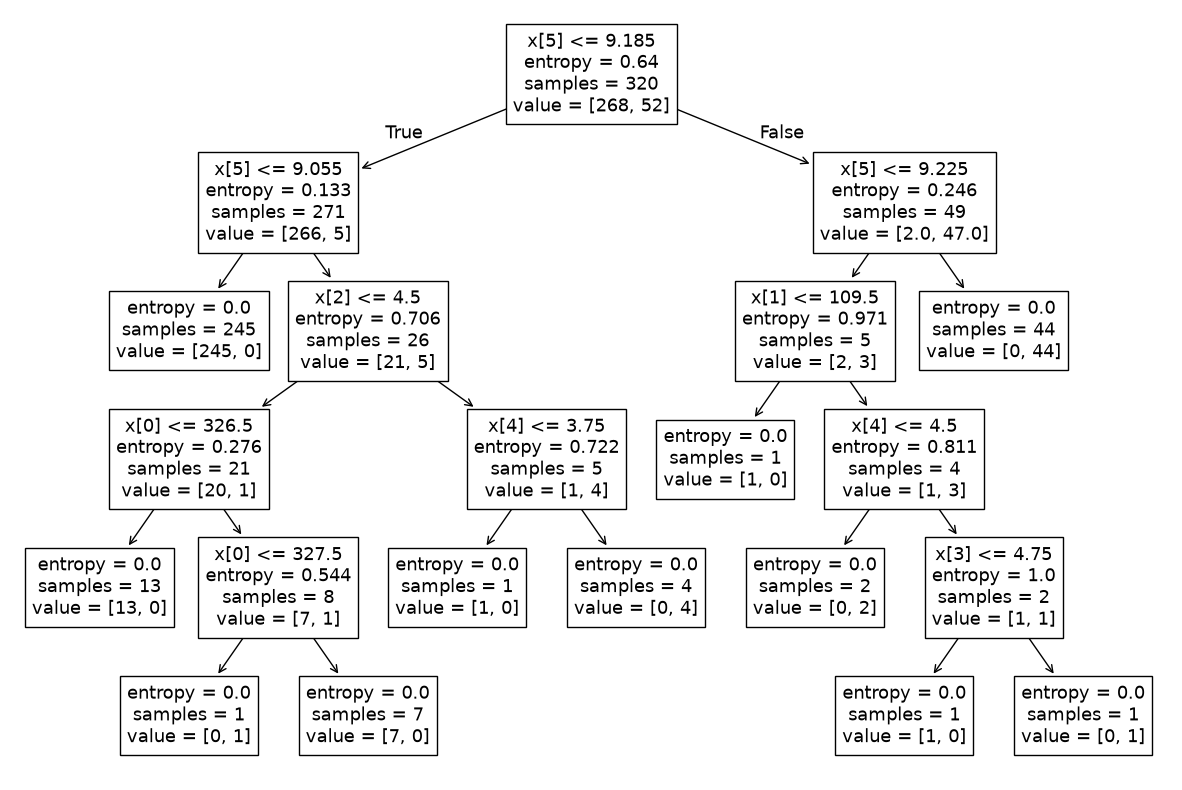

In [21]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(15,10))
plot_tree(ap_entropy)
plt.show()

In [22]:
ap_gini = DecisionTreeClassifier(criterion='gini')
ap_gini.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [23]:
y_pred1_ginni = ap_gini.predict(X_train)

In [24]:
confusion_matrix(y_train,y_pred1_ginni)

array([[268,   0],
       [  0,  52]])

In [25]:
accuracy_gini = accuracy_score(y_train,y_pred1_ginni)
precision_gini = precision_score(y_train,y_pred1_ginni)
recall_gini = recall_score(y_train,y_pred1_ginni)
f1_gini = f1_score(y_train,y_pred1_ginni)
print(f"Accuracy: {accuracy_gini}")
print(f"Precision: {precision_gini}")
print(f"Recall: {recall_gini}")
print(f"F1 Score: {f1_gini}")

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [26]:
y_pred_ginni = ap_gini.predict(X_test)

In [27]:
confusion_matrix(y_test,y_pred_ginni)

array([[59,  3],
       [ 1, 17]])

In [28]:
accuracy_gini = accuracy_score(y_test,y_pred_ginni)
precision_gini = precision_score(y_test,y_pred_ginni)
recall_gini = recall_score(y_test,y_pred_ginni)
f1_gini = f1_score(y_test,y_pred_ginni)
print(f"Accuracy: {accuracy_gini}")
print(f"Precision: {precision_gini}")
print(f"Recall: {recall_gini}")
print(f"F1 Score: {f1_gini}")

Accuracy: 0.95
Precision: 0.85
Recall: 0.9444444444444444
F1 Score: 0.8947368421052632


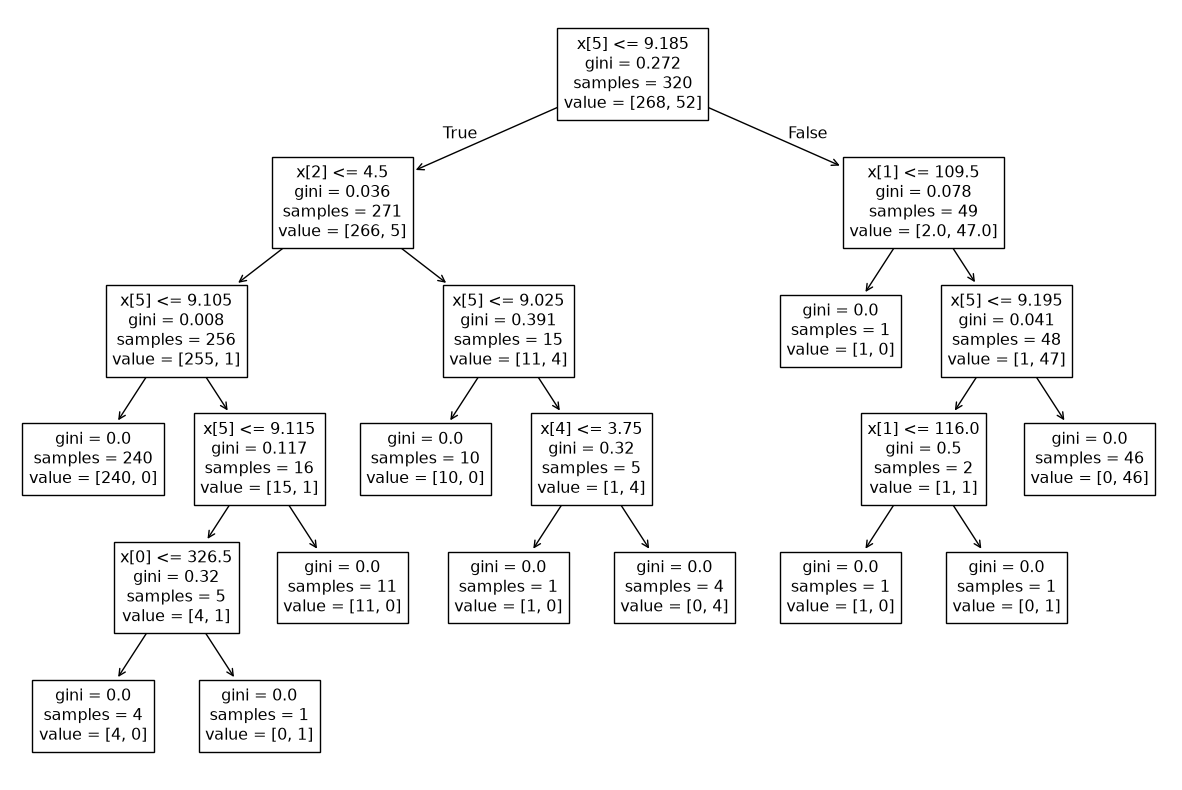

In [29]:
plt.figure(figsize=(15,10))
plot_tree(ap_gini)
plt.show()

Naive Bayes classifier

In [30]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[268., 52.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.84,0.16]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.271e-07
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['GRE Score','TOEFL Score','University Rating',...,'LOR','CGPA','Research']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 7)","[[313.84,105.84, 2.77,..., 3.26, 8.42, 0.45], [332.35,115.73, 4.6 ,..., 4.42, 9.45, 0.98]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 7)","[[90.87,25.67, 0.96,..., 0.69, 0.23, 0.25], [26.92, 8.66, 0.32,..., 0.24, 0.05, 0.02]]"


In [31]:
y_pred_nb = nb.predict(X_train)

In [32]:
confussion_matrix_nb = confusion_matrix(y_train,y_pred_nb)
confussion_matrix_nb

array([[251,  17],
       [  2,  50]])

In [33]:
accuracy_nb = accuracy_score(y_train,y_pred_nb)
precision_nb = precision_score(y_train,y_pred_nb)
recall_nb = recall_score(y_train,y_pred_nb)
f1_nb = f1_score(y_train,y_pred_nb)
print(f"Accuracy: {accuracy_nb}")
print(f"Precision: {precision_nb}")
print(f"Recall: {recall_nb}")
print(f"F1 Score: {f1_nb}")

Accuracy: 0.940625
Precision: 0.746268656716418
Recall: 0.9615384615384616
F1 Score: 0.8403361344537815


In [34]:
y_pred1_nb = nb.predict(X_test)

In [35]:
confussion_matrix_nb = confusion_matrix(y_test,y_pred1_nb)
confussion_matrix_nb

array([[57,  5],
       [ 1, 17]])

In [36]:
accuracy_nb = accuracy_score(y_test,y_pred1_nb)
precision_nb = precision_score(y_test,y_pred1_nb)
recall_nb = recall_score(y_test,y_pred1_nb)
f1_nb = f1_score(y_test,y_pred1_nb)
print(f"Accuracy: {accuracy_nb}")
print(f"Precision: {precision_nb}")
print(f"Recall: {recall_nb}")
print(f"F1 Score: {f1_nb}")

Accuracy: 0.925
Precision: 0.7727272727272727
Recall: 0.9444444444444444
F1 Score: 0.85


In [37]:
X_train

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
3,322,110,3,3.5,2.5,8.67,1.0
18,318,110,3,4.0,3.0,8.80,0.0
202,340,120,5,4.5,4.5,9.91,1.0
250,320,104,3,3.0,2.5,8.57,1.0
274,315,100,1,2.0,2.5,7.95,0.0
...,...,...,...,...,...,...,...
71,336,112,5,5.0,5.0,9.76,1.0
106,329,111,4,4.5,4.5,9.18,1.0
270,306,105,2,2.5,3.0,8.22,1.0
348,302,99,1,2.0,2.0,7.25,0.0


In [38]:
x = X_train[['GRE Score','TOEFL Score']]

In [39]:
nb1 = GaussianNB()
nb1.fit(x,y_train)
y_pred_new= nb1.predict(x)

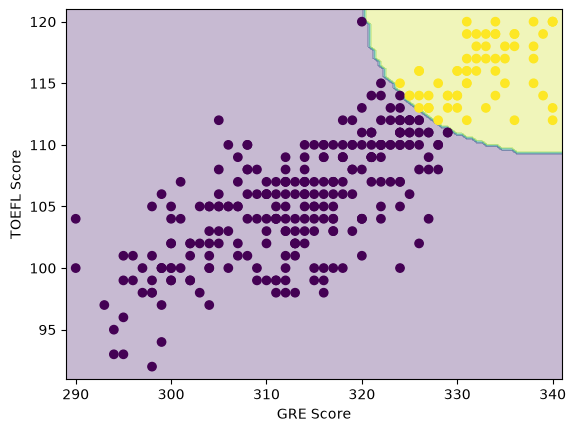

In [40]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

DecisionBoundaryDisplay.from_estimator(nb1,x,response_method='predict',alpha=0.3)
plt.scatter(x['GRE Score'] ,x['TOEFL Score'],c =y_pred_new )

User Input

In [41]:
Ap

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [42]:

gre = float(input("GRE Score (290-340): "))
toefl = float(input("TOEFL Score (90-120): "))
rating = float(input("University Rating (1-5): "))
sop = float(input("SOP Strength (1-5): "))
lor = float(input("LOR Strength (1-5): "))
cgpa = float(input("CGPA (1-10): "))
research = float(input("Research Experience (1 for Yes, 0 for No): "))

new_data = pd.DataFrame([{
    "GRE Score": gre,
    "TOEFL Score": toefl,
    "University Rating": rating,
    "SOP": sop,
    "LOR": lor,
    "CGPA": cgpa,
    "Research": research
}])

new_data = new_data[X.columns]


GRE Score (290-340):  240
TOEFL Score (90-120):  100
University Rating (1-5):  4
SOP Strength (1-5):  3
LOR Strength (1-5):  2
CGPA (1-10):  8
Research Experience (1 for Yes, 0 for No):  1


Prediction Through Entropy Model

In [43]:
prediction = ap_entropy.predict(new_data)
if prediction == 0:
  print('You are not eligible for admission')
else:
  print('You are eligible for admission')

You are not eligible for admission


Prediction Through Ginny Index Model

In [44]:
prediction = ap_gini.predict(new_data)
if prediction == 0:
  print('You are not eligible for admission')
else:
  print('You are eligible for admission')

You are not eligible for admission


Prediction Through Naive Bayes classifier model

In [45]:
prediction = nb.predict(new_data)
if prediction == 0:
  print('You are not eligible for admission')
else:
  print('You are eligible for admission')

You are not eligible for admission
